Epoch 1/10
206/206 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0233
Epoch 2/10
206/206 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0132
Epoch 3/10
206/206 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0106
Epoch 4/10
206/206 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0091
Epoch 5/10
206/206 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0084
Epoch 6/10
206/206 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0080
Epoch 7/10
206/206 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0077
Epoch 8/10
206/206 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0075
Epoch 9/10
206/206 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0072
Epoch 10/10
206/206 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0070
824/824 ━━━━━━━━━━━━━━━━━━━━ 0s 314us/step
225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 325us/step
Threshold: 0.012808713529420394


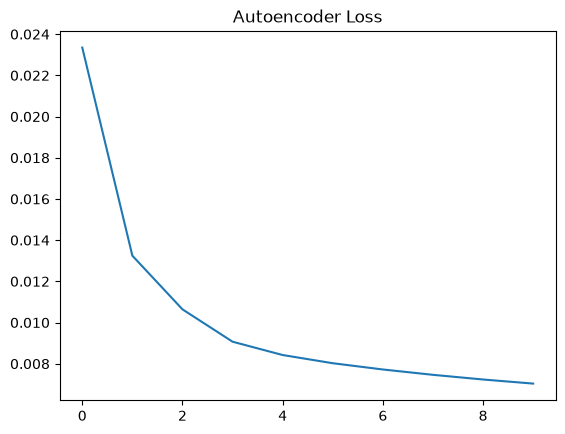

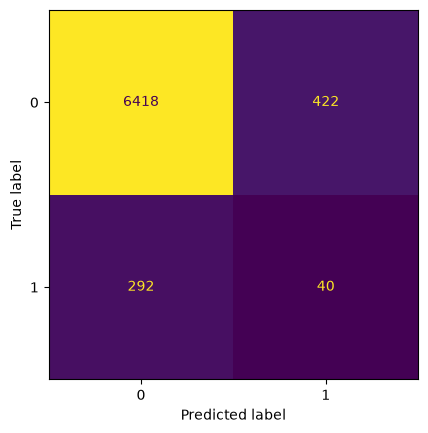

In [6]:

import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay

# 1. Load dataset
train = pd.read_csv('AutoEncoder/Sign Language MNIST/sign_mnist_train.csv')
test = pd.read_csv('AutoEncoder/Sign Language MNIST/sign_mnist_test.csv')

X_train = train.drop('label', axis=1)
y_train = train['label']

X_test = test.drop('label', axis=1)
y_test = test['label']

# 2. Preprocess data
X_train = X_train / 255.0
X_test = X_test / 255.0

# 3. Take only normal classes
X_train = X_train[y_train != 24]

# 4. Build Autoencoder
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(784, activation='sigmoid')
])

# 5. Compile model
model.compile(optimizer='adam', loss='mse')

# 6. Train model
history = model.fit(
    X_train, X_train,
    epochs=10,
    batch_size=128
)

# 7. Calculate error and detect anomalies
train_pred = model.predict(X_train)
train_error = np.mean((X_train - train_pred)**2, axis=1)

threshold = np.percentile(train_error, 95)

test_pred = model.predict(X_test)
test_error = np.mean((X_test - test_pred)**2, axis=1)

y_pred = (test_error > threshold).astype(int)
y_true = (y_test == 24).astype(int)

# 8. Evaluate and plot
print("Threshold:", threshold)


plt.plot(history.history['loss'])
plt.title('Autoencoder Loss')
plt.show()
ConfusionMatrixDisplay.from_predictions(y_true, y_pred,colorbar=False)